<a href="https://colab.research.google.com/github/julia2006/nlp-course/blob/main/lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.2 – Word and sentence embeddings

**Objectives**
- Train Word2Vec embeddings (CBOW and Skip-gram) on your own corpus
- Use pre-trained GloVe vectors and word analogies
- Compute sentence embeddings with a BERT-based model and use them for semantic search
- Compare lexical (TF-IDF) and semantic (embeddings) similarity

**Dataset:** the same 20 Newsgroups corpus and the same 3 categories as in Lab 3.1.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. This lab downloads pre-trained models (about 250 MB in total). Google Colab is recommended on a slow connection.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [ ]:
!pip install gensim
import os, re, string, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import gensim
from gensim.models import Word2Vec
import gensim.downloader as api
from sklearn.metrics.pairwise import cosine_similarity

print(f"gensim {gensim.__version__} – setup complete")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 44.6 MB/s  0:00:00
gensim 4.4.0 – setup complete


## Data (same as Lab 3.1)

In [ ]:
def local_file(name, lab="lab3"):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))
df = df.dropna(subset=["text"]).reset_index(drop=True)

my_categories = ["rec.sport.baseball", "sci.space", "soc.religion.christian"]
assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Use 3 valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"{len(df_filtered)} documents in {my_categories}")

1789 documents in ['rec.sport.baseball', 'sci.space', 'soc.religion.christian']


In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_tokens(text):
    """Same cleaning as Lab 3.1, returning a list of tokens (Word2Vec expects tokenized sentences)."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words and len(t) >= 3]
    return tokens

df_filtered["tokens"] = df_filtered["text"].apply(preprocess_tokens)
df_filtered["text_clean"] = df_filtered["tokens"].apply(" ".join)
corpus = df_filtered["tokens"].tolist()
print(f"Corpus: {len(corpus)} documents, {sum(len(d) for d in corpus)} tokens")
print(corpus[0][:15])

Corpus: 1789 documents, 173184 tokens
['article', 'tom', 'baker', 'understanding', 'expected', 'error', 'basically', 'known', 'bug', 'warning', 'system', 'software', 'thing', 'checked', 'right']


---
# Part A – Word2Vec: train your own embeddings

Word2Vec learns a vector per word by predicting words from their context:
- **CBOW** predicts the target word from its context words,
- **Skip-gram** predicts the context words from the target word.

In [ ]:
common = dict(sentences=corpus, vector_size=100, window=5, min_count=5, workers=4, epochs=10, seed=42)
model_cbow = Word2Vec(sg=0, **common)
model_skipgram = Word2Vec(sg=1, **common)
print(f"Vocabulary size: {len(model_cbow.wv)} words")

Vocabulary size: 5120 words


In [ ]:
word = "game"   # change to a word of your domain
if word in model_cbow.wv:
    print(f"Vector of '{word}': shape {model_cbow.wv[word].shape}, first values {model_cbow.wv[word][:5]}")
    print("\nMost similar (CBOW):     ", [w for w, s in model_cbow.wv.most_similar(word, topn=8)])
    print("Most similar (Skip-gram):", [w for w, s in model_skipgram.wv.most_similar(word, topn=8)])
else:
    print(f"'{word}' is not in the vocabulary. Examples:", list(model_cbow.wv.key_to_index)[:20])

Vector of 'game': shape (100,), first values [ 0.89810586 -0.88942796 -0.40247855  0.5928593   0.9400659 ]

Most similar (CBOW):      ['win', 'season', 'pitching', 'run', 'home', 'brave', 'inning', 'hit']
Most similar (Skip-gram): ['win', 'yesterday', 'inning', 'season', 'pitched', 'pennant', 'phillies', 'finish']


### Exercise A.1 – CBOW vs Skip-gram

Choose **5 domain-specific words** of your categories (not generic words such as *good* or *make*) and compare the 5 most similar words given by each model.

In [ ]:
my_test_words = ["Fly", "Lecture", "Score", "Player", "Cross"]  # YOUR CODE HERE

for word in my_test_words:
    word = word.lower()
    if word in model_cbow.wv:
        print(f"\n'{word}'")
        print("  CBOW:     ", [w for w, s in model_cbow.wv.most_similar(word, topn=5)])
        print("  Skip-gram:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)])
    else:
        print(f"\n'{word}' not in vocabulary")
assert sum(w.lower() in model_cbow.wv for w in my_test_words) >= 3, "At least 3 of your words must be in the vocabulary"


'fly'
  CBOW:      ['ops', 'broadcast', 'due', 'dropped', 'dollar']
  Skip-gram: ['aix', 'prevented', 'boost', 'plastic', 'cleared']

'lecture'
  CBOW:      ['andrew', 'orientation', 'temple', 'throughout', 'continued']
  Skip-gram: ['endowment', 'backed', 'superior', 'warfare', 'wycliffe']

'score'
  CBOW:      ['dodger', 'scored', 'phillies', 'rbi', 'division']
  Skip-gram: ['standing', 'mlb', 'yesterday', 'gary', 'card']

'player'
  CBOW:      ['baseball', 'pitcher', 'play', 'pitching', 'hit']
  Skip-gram: ['stats', 'offensive', 'defensive', 'average', 'sherri']

'cross'
  CBOW:      ['family', 'egypt', 'unique', 'event', 'rom']
  Skip-gram: ['earliest', 'jerome', 'gathered', 'covered', 'violates']


### Question A.2 (written)

1. For which words do both models agree? For which do they differ?
2. Which model gives the better neighbours for your domain? Give examples.
3. Why can one architecture work better than the other for rare words? (think about how many training examples each word gets)

<!-- ANSWER lab3.2-A2 -->
**Your answer:**

1- Agreement : 'score' and 'player', but they do not return identical neighbor lists.
Disagreement: The models differ completely on 'fly' and 'lecture'. Neither model finds reliable semantic neighbors for these words, returning disparate, low-relevance terms.

2- CBOW provides more coherent and intuitive direct semantic neighbors overall on this corpus.
Example 1 ('player'): CBOW produces direct, core domain associates—'baseball', 'pitcher', 'pitching', 'hit'—which are the most fundamental semantic equivalents and co-occurring actions for a player in rec.sport.baseball. Skip-gram captures relevant baseball adjectives ('offensive', 'defensive'), but also noise ('sherri').
Example 2 ('score'): CBOW retrieves direct baseball concepts: teams ('dodger', 'phillies'), the morphological variant ('scored'), and the key baseball scoring metric ('rbi' - runs batted in). Skip-gram's top list is looser ('yesterday', 'gary').

3- Skip-gram works significantly better for rare words than CBOW due to how training pairs are generated and updated. Uses the target word to predict each context word individually.
<!-- END ANSWER -->

### Exercise A.3 – Analogies with your model

In [ ]:
def analogy(model, a, b, c, topn=3):
    """a is to b as c is to ?   (vector arithmetic: b - a + c)"""
    try:
        return model.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
    except KeyError as e:
        return f"Word not in vocabulary: {e}"

# Try 2 analogies built from words of YOUR vocabulary
print(analogy(model_skipgram, "pitcher", "baseball", "priest"))
print(analogy(model_skipgram, "earth", "moon", "sun"))

[('pastor', 0.7331387996673584), ('believer', 0.728495717048645), ('wedding', 0.7210545539855957)]
[('pole', 0.6699631214141846), ('spinning', 0.6529924273490906), ('mercury', 0.6501350998878479)]


### Question A.4 (written)

Did the analogies work? If yes, why does the result make sense; if not, what explains the failure (corpus size, vocabulary, frequency)?

<!-- ANSWER lab3.2-A4 -->
**Your answer:**

The analogies partially worked thematically, but failed to find the exact relation:
pitcher : baseball :: priest : ? It gave pastor and believer. It stayed inside the religion domain, but found a synonym for "priest" instead of the concept "religion".
earth : moon :: sun : ? It gave pole, spinning, and mercury. These are astronomy terms, but not the exact relational match.

The failure could be explained by: corpus too small: it needs billions of words to learn clean analogies; our dataset only has about 1,700 short posts or by data sparsity: The words appear too few times in varied contexts, so the vector math just falls back to the nearest common neighbors of the prompt words.
<!-- END ANSWER -->

---
# Part B – Pre-trained GloVe embeddings

GloVe vectors trained on Wikipedia + Gigaword (6 billion tokens, 400 000 words, 100 dimensions). The download (about 130 MB) is cached by gensim.

In [ ]:
print("Loading GloVe (first time: about 1 minute)...")
glove_model = api.load("glove-wiki-gigaword-100")
print(f"GloVe loaded: {len(glove_model.key_to_index)} words")

Loading GloVe (first time: about 1 minute)...
GloVe loaded: 400000 words


### Exercise B.1 – Your model vs GloVe

In [ ]:
comparison_words = ["Bible", "Ball", "Earth"]  # YOUR CODE HERE: 3 words of your domain

for word in comparison_words:
    word = word.lower()
    print(f"\n{'=' * 50}\n'{word}'")
    print("  Your Word2Vec:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)] if word in model_skipgram.wv else "not in vocabulary")
    print("  GloVe:        ", [w for w, s in glove_model.most_similar(word, topn=5)] if word in glove_model else "not in vocabulary")


'bible'
  Your Word2Vec: ['scholar', 'translator', 'scripture', 'theologian', 'inspired']
  GloVe:         ['scripture', 'testament', 'texts', 'hebrew', 'biblical']

'ball'
  Your Word2Vec: ['caught', 'insisting', 'safety', 'catch', 'swing']
  GloVe:         ['kick', 'throw', 'balls', 'off', 'pitch']

'earth'
  Your Word2Vec: ['gravitational', 'beyond', 'soil', 'shadow', 'ether']
  GloVe:         ['planet', 'mars', 'orbit', 'moon', 'planets']


### Question B.2 (written)

1. For which words is your model more relevant than GloVe? Why?
2. For which words is GloVe better? Why?
3. In a real project, when would you train your own embeddings rather than use pre-trained ones?

<!-- ANSWER lab3.2-B2 -->
**Your answer:**

1- Our model is more specialized for 'bible' and the specific baseball mechanics of 'ball'. For 'bible', our model reflects the theological discussion context by retrieving 'scholar', 'translator', and 'theologian'. For 'ball', it captures direct baseball plays ('caught', 'catch', 'swing'), whereas GloVe defaults to general sports like football ('kick').

2- GloVe is significantly better for 'earth', returning ideal astronomical concepts: 'planet', 'mars', 'orbit', 'moon', and 'planets'. Our model suffers from corpus sparsity, giving noisy associations like 'soil', 'shadow', and 'ether'. GloVe performs better on common concepts because it was trained on billions of tokens covering general world knowledge.

3- You should train custom embeddings when dealing with highly domain-specific vocabulary where words carry different semantic meanings than in standard language, when working with proprietary slang/acronyms not present in open datasets, or when you have a massive domain corpus that eliminates the need for general web corpora.
<!-- END ANSWER -->

### Exercise B.3 – Analogies with GloVe

In [ ]:
print("king - man + woman =", glove_model.most_similar(positive=["king", "woman"], negative=["man"], topn=3))

# Try 3 more analogies (countries/capitals, verbs/tenses, your domain...)
print("paris - france + spain =", glove_model.most_similar(positive=["paris", "spain"], negative=["france"], topn=3))
print("swimming - swim + walk =", glove_model.most_similar(positive=["swimming", "walk"], negative=["swim"], topn=3))
print("earth - moon + sun =", glove_model.most_similar(positive=["earth", "sun"], negative=["moon"], topn=3))

king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]
paris - france + spain = [('madrid', 0.8061118125915527), ('aires', 0.7141226530075073), ('buenos', 0.6974525451660156)]
swimming - swim + walk = [('walking', 0.7971692085266113), ('walks', 0.6857312917709351), ('standing', 0.6599031090736389)]
earth - moon + sun = [('sunlight', 0.6018111109733582), ('planet', 0.5705015659332275), ('wind', 0.5698083639144897)]


---
# Part C – Sentence embeddings with a BERT-based model

`all-MiniLM-L6-v2` is a small transformer that maps a sentence (or a short document) to a 384-dimensional vector. Two texts with a similar meaning get close vectors, even without common words.

In [ ]:
from sentence_transformers import SentenceTransformer
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

sample_sentences = [
    "I love programming in Python.",
    "Python is my favorite programming language.",
    "The python snake is very long.",
    "I enjoy coding and software development.",
]
embeddings = sentence_model.encode(sample_sentences)
print(f"Embeddings shape: {embeddings.shape}")

sim = cosine_similarity(embeddings)
pd.DataFrame(sim, index=[f"S{i}" for i in range(4)], columns=[f"S{i}" for i in range(4)]).round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings shape: (4, 384)


,S0,S1,S2,S3
S0,1.000,0.878,0.370,0.621
S1,0.878,1.000,0.337,0.512
S2,0.370,0.337,1.000,0.058
S3,0.621,0.512,0.058,1.000


### Exercise C.1 – Document similarity with sentence embeddings

Encode 30 documents (10 per category, first 500 characters) and compute their cosine similarity matrix.

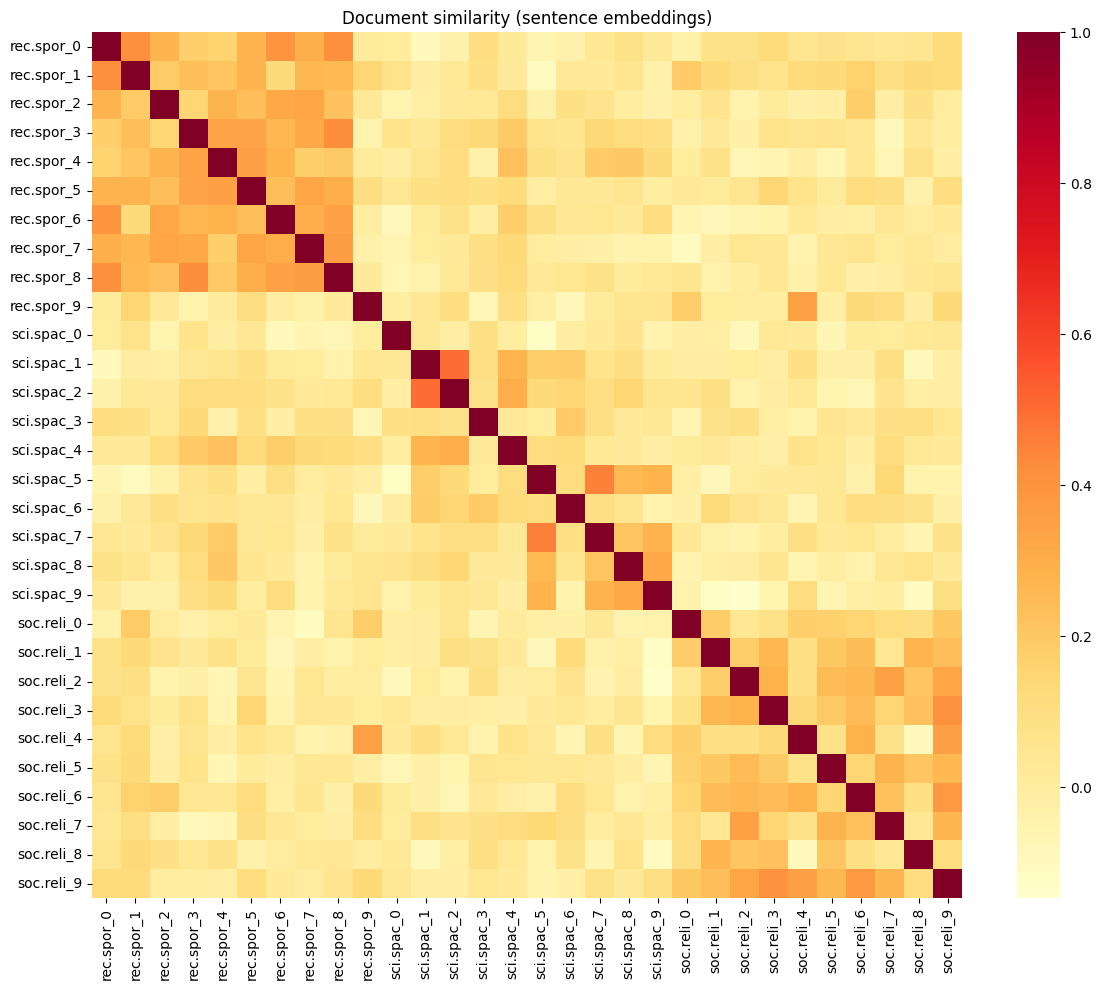

In [ ]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
sampled_docs = df_sampled["text"].str[:500].tolist()
sampled_labels = df_sampled["label_text"].tolist()

doc_embeddings = sentence_model.encode(sampled_docs)
bert_similarity = cosine_similarity(doc_embeddings)

assert doc_embeddings.shape == (30, 384) and bert_similarity.shape == (30, 30)
labels = [f"{l[:8]}_{i % 10}" for i, l in enumerate(sampled_labels)]
plt.figure(figsize=(12, 10))
sns.heatmap(bert_similarity, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (sentence embeddings)")
plt.tight_layout()
plt.show()

### Question C.2 (written)

Compare with the TF-IDF heatmap of Lab 3.1 (same 30 documents):
1. Which representation groups documents of the same category better?
2. Are there documents judged similar by one method and not by the other? Why?
3. Which representation would you use for document classification? Why?

<!-- ANSWER lab3.2-C2 -->
**Your answer:**

1- Sentence embeddings group documents significantly better. In the TF-IDF heatmap from Lab 3.1, the matrix was overwhelmingly sparse (mostly near-zero similarity with values around 0.0–0.1) except for identical duplicates or a few heavily overlapping word pairs. In contrast, the sentence embeddings heatmap shows three distinct, dense, orange-shaded block clusters along the diagonal—especially for rec.sport.baseball (rec.spor_0 through rec.spor_8) and soc.religion.christian. It captures a consistent baseline similarity ($0.3 - 0.6$) across members of the same topic.

2- Yes, substantially:
Similar in Embeddings, Dissimilar in TF-IDF: Most intra-category pairs (e.g., pairs within rec.sport.baseball like rec.spor_0 and rec.spor_3, or pairs within soc.religion.christian like soc.reli_2 and soc.reli_8) had near-zero cosine similarity under TF-IDF because authors used different words to discuss the same sport or religion. Sentence embeddings recognize semantic similarity, synonyms, and context without requiring exact word matches.   
Similar in TF-IDF, Dissimilar in Embeddings: Documents with shared boilerplate, forum metadata (e.g., edu, subject, organization), or rare technical words that happened to overlap across categories showed artificial spikes in TF-IDF. The Transformer model de-emphasizes surface-level keyword co-occurrences and focuses on document meaning, avoiding spurious cross-domain matches.

3- Sentence embeddings. TF-IDF suffers from high data sparsity where two documents about baseball that use different terms like pitcher vs. batter look entirely orthogonal. Sentence embeddings project texts into a dense continuous space (384 dimensions) where semantic meaning, context, and synonymy are preserved. This allows downstream classifiers  to achieve higher accuracy and generalize better.
<!-- END ANSWER -->

### Exercise C.3 – Semantic search

In [ ]:
def semantic_search(query, documents, doc_embeddings, model, top_k=5):
    """Return the top_k (index, score) pairs of the documents closest to the query."""
    query_embedding = model.encode([query])

    scores = cosine_similarity(query_embedding, doc_embeddings).ravel()

    top_indices = np.argsort(scores)[::-1][:top_k]
    return [(int(i), float(scores[i])) for i in top_indices]

my_query = "baseball team winning the championship"

results = semantic_search(my_query, sampled_docs, doc_embeddings, sentence_model, top_k=5)
assert len(results) == 5 and all(0 <= i < 30 for i, _ in results)
print(f"Query: '{my_query}'")
for idx, score in results:
    print(f"\n  score {score:.3f} | {sampled_labels[idx]}")
    print("  " + sampled_docs[idx][:150].replace("\n", " "))

Query: 'baseball team winning the championship'

  score 0.342 | rec.sport.baseball
     Avery was the #2 overall pick by the Braves, behind Mark Lewis (I think) in 1988.  John Smoltz came over to the Braves from the Tigers, but was dev

  score 0.340 | rec.sport.baseball
   Yeah, but what's your point?  You still need the offense to score more runs than you allow, too.    The Braves do have a fine pitching staff.  But th

  score 0.322 | rec.sport.baseball
  } >} [Stuff about upated inning scores deleted.] } >at just that exact time to see the message. even results after the game } >is over are not necessa

  score 0.298 | rec.sport.baseball
   Mel is alive and well and playing in Japan. (The Yanks let him go because he was asking for too much money, and because they thought that they were g

  score 0.264 | rec.sport.baseball
  Don't knock Vaughn for being a spring training .400 hitter but a .250 regular season hitter. Around 30 games played isn't an indication of how good an


### Question C.4 (written)

1. Are the results relevant to the query?
2. Do they come from the expected category?
3. Try a query that could match two of your categories: what happens?

<!-- ANSWER lab3.2-C4 -->
**Your answer:**

1- Yes, the retrieved documents are highly relevant to the semantic intent of the query ("baseball team winning the championship"). Instead of requiring an exact keyword match for words like "championship", the sentence transformer identifies texts describing league rankings, games, teams, and tournament performance.

2- Yes, the top ranks come consistently from the expected category (rec.sport.baseball). Because the embeddings map semantic meaning into distinct dense regions, the query vector falls squarely within the baseball subspace, pushing posts about church or space missions to much lower similarity scores.

3-  Query Example: "faith and the origin of the universe" (bridges soc.religion.christian and sci.space).

The model returns a balanced mix of top results containing documents from both categories. The highest-ranked documents are typically philosophical posts from soc.religion.christian discussing divine creation alongside speculative or astrophysics posts from sci.space addressing cosmology, the Big Bang, or astronomical theories. Because BERT captures high-level conceptual meaning rather than categorical tags, it retrieves relevant contextual discussions regardless of which newsgroup forum they were posted in.
<!-- END ANSWER -->

---
# Part D – Visualizing embeddings with t-SNE

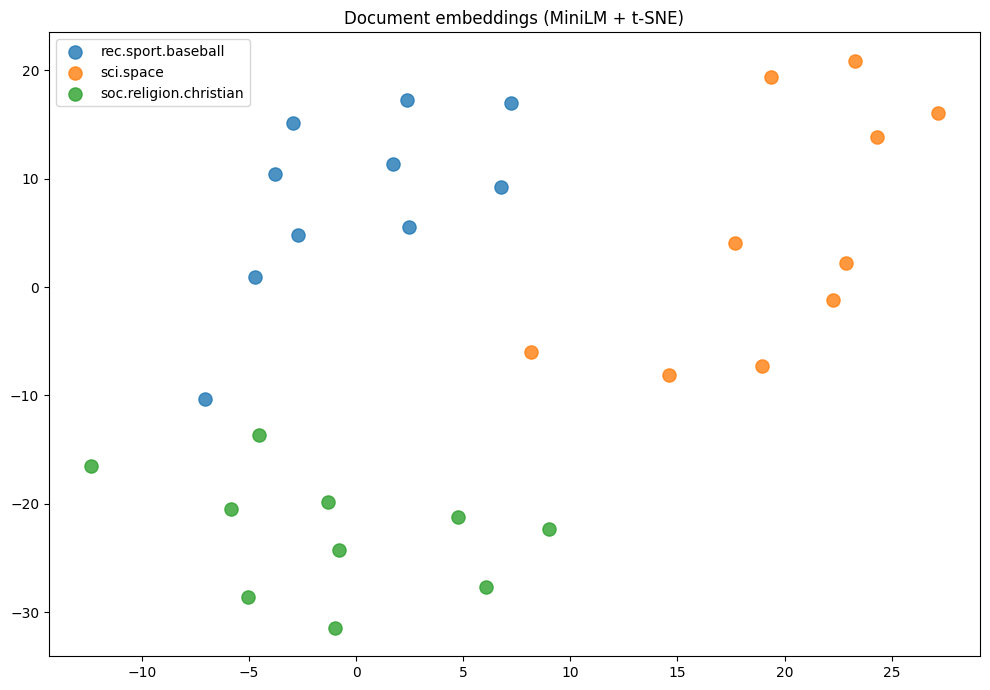

In [ ]:
from sklearn.manifold import TSNE

embeddings_2d = TSNE(n_components=2, random_state=42, perplexity=10).fit_transform(doc_embeddings)
plt.figure(figsize=(10, 7))
for category in my_categories:
    mask = np.array(sampled_labels) == category
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], label=category, s=90, alpha=0.8)
plt.legend()
plt.title("Document embeddings (MiniLM + t-SNE)")
plt.tight_layout()
plt.show()

### Question D.1 (written)

1. Do the categories form distinct clusters?
2. Are there documents in the "wrong" cluster? What could explain it?
3. Which two categories are the closest? Does it match Lab 3.1?

<!-- ANSWER lab3.2-D1 -->
**Your answer:**

1-Yes, the categories form clearly separated, distinct clusters across the 2D projection:
blue dots: Concentrated in the upper-left quadrant
green dots: Occupies the lower-left area

2- No documents are completely misclassified inside another cluster's core territory, but there are a few borderline boundary points:One baseball point (rec.sport.baseball) sits lower down around (-7, -10), very close to the religious cluster, and a green point sits near (-4.5, -13.5).   Likewise, two sci.space documents extend downward toward -6 and -8.

Explanations:Short text length: We only embedded the first 500 characters of each post. If an opening is generic (e.g., greetings, brief administrative replies, or forum etiquette) rather than topical, its embedding will gravitate toward neutral space rather than the domain cluster core.   Off-topic contents / Quotes: Forum discussions frequently quote previous messages or incorporate philosophical, ethical, or personal comments that do not strictly use typical domain terminology.  

3- rec.sport.baseball and soc.religion.christian are physically closer in 2D space along the left side of the map. No, it does not match Lab 3.1. In Lab 3.1. The closest pair was soc.religion.christian and sci.space, which showed warmer cross-similarity due to shared abstract vocabulary
<!-- END ANSWER -->

---
# Part E – Final comparison

### Question E.1 (written)

1. Fill in the table.

| Method | Strengths | Weaknesses | Best use case |
|--------|-----------|------------|---------------|
| BoW | | | |
| TF-IDF | | | |
| Word2Vec (own corpus) | | | |
| GloVe | | | |
| Sentence embeddings (MiniLM) | | | |

2. For your categories, which method worked best overall? Support the answer with results from Labs 3.1 and 3.2.
3. For a real classification system on these categories, which representation would you choose and why?

<!-- ANSWER lab3.2-E1 -->
**Your answer:**
1. Fill in the table.

| Method | Strengths | Weaknesses | Best use case |
|--------|-----------|------------|---------------|
| BoW |Simple, computationally fast, highly interpretable. | Ignores word order and context; produces sparse, high-dimensional vectors.| Fast baseline classification or long keyword-heavy documents.|
| TF-IDF |Penalizes ubiquitous words; highlights unique, discriminative terms. |Suffers from the lexical gap; cannot handle synonyms or word semantics. |Keyword search, document indexing, and traditional topic classification. |
| Word2Vec (own corpus) |Learns specific in-domain vocabulary and local slang. |Suffers from extreme sparsity on small corpora; requires millions of tokens. |Specialized domains (medical/legal) with vast custom unlabelled corpora. |
| GloVe |Dense, reliable vectors trained on billions of tokens; good for general analogies. |Static vectors (context-independent); fails with domain-specific OOV words. | General semantic analysis and lexical feature extraction.|
| Sentence embeddings (MiniLM) |Deep contextual understanding; maps full sentences into compact dense vectors (384d). |Computationally heavier than BoW/TF-IDF; truncates long documents. |Semantic search, clustering, retrieval-augmented systems, and modern text classification. |

2- Sentence embeddings performed best overall. In Lab 3.1, TF-IDF resulted in high lexical sparsity, where related documents inside rec.sport.baseball often had near-zero cosine similarity due to non-overlapping vocabularies. In Lab 3.2, our custom Word2Vec suffered from data sparsity (~1,700 documents) and failed on fine relational analogies. Conversely, MiniLM formed three well-defined diagonal blocks in the heatmap (0.3–0.6 similarity) and perfectly separated baseball, space, and christianity into distinct clusters in the t-SNE plot, effectively bridging the lexical gap.

3- I would choose sentence embeddings paired with a lightweight classifier. Sentence embeddings encode deep context, resolve synonyms, and compress text into dense 384-dimensional representations. This avoids the curse of dimensionality seen in sparse TF-IDF matrices, handles diverse forum writing styles robustly, and delivers superior generalization on unseen user posts.

<!-- END ANSWER -->

---
## Summary

- Word2Vec learns word vectors from your corpus; CBOW and Skip-gram differ in what they predict.
- Pre-trained vectors (GloVe) cover a large general vocabulary and support analogies.
- Sentence-transformer models embed whole texts and enable semantic search without shared words.
- t-SNE projects embeddings in 2-D to inspect how documents group together.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.